In [1]:
!pip install torchtext==0.4.0 -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.1/53.1 kB 1.3 MB/s eta 0:00:00


In [2]:
from torchtext import data, datasets
import torch
# For tokenization
TEXT = data.Field(tokenize='spacy',
                  tokenizer_language='en_core_web_sm',
                  include_lengths = True)
# For multi-class classification labels
LABEL = data.LabelField()
# Load the TREC dataset
# train_data, test_data = datasets.TREC.splits(TEXT, LABEL, fine_grained=False)
train_data, test_data = datasets.TREC.splits(TEXT, LABEL, fine_grained=False)

downloading train_5500.label


train_5500.label: 100%|██████████| 336k/336k [00:00<00:00, 1.16MB/s]


downloading TREC_10.label


TREC_10.label: 100%|██████████| 23.4k/23.4k [00:00<00:00, 355kB/s]


In [3]:
TEXT.build_vocab(train_data,
                max_size=25000,
                vectors="glove.6B.100d",
                # min_freq=3,
                unk_init=torch.Tensor.normal_)
LABEL.build_vocab(train_data)

.vector_cache/glove.6B.zip: 862MB [02:40, 5.39MB/s]                           
100%|█████████▉| 399999/400000 [00:18<00:00, 21551.59it/s]


Using device: cuda

Vocab size: 9330
Classes: 6
Embedding dim: 100

TRAINING CNN
Epoch 01 | Train Loss: 1.231 Acc: 52.17% | Valid Loss: 0.914 Acc: 65.69%
Epoch 02 | Train Loss: 0.738 Acc: 74.06% | Valid Loss: 0.704 Acc: 74.50%
Epoch 03 | Train Loss: 0.517 Acc: 82.02% | Valid Loss: 0.593 Acc: 77.17%
Epoch 04 | Train Loss: 0.361 Acc: 87.69% | Valid Loss: 0.554 Acc: 79.01%
Epoch 05 | Train Loss: 0.267 Acc: 91.54% | Valid Loss: 0.563 Acc: 81.21%
Epoch 06 | Train Loss: 0.184 Acc: 94.49% | Valid Loss: 0.509 Acc: 80.93%
Epoch 07 | Train Loss: 0.130 Acc: 96.21% | Valid Loss: 0.574 Acc: 80.40%
Epoch 08 | Train Loss: 0.091 Acc: 97.39% | Valid Loss: 0.532 Acc: 82.38%
Epoch 09 | Train Loss: 0.064 Acc: 98.27% | Valid Loss: 0.548 Acc: 82.56%
Epoch 10 | Train Loss: 0.053 Acc: 98.66% | Valid Loss: 0.601 Acc: 82.00%
Epoch 11 | Train Loss: 0.036 Acc: 99.32% | Valid Loss: 0.572 Acc: 82.74%
Epoch 12 | Train Loss: 0.028 Acc: 99.46% | Valid Loss: 0.576 Acc: 83.25%
Epoch 13 | Train Loss: 0.023 Acc: 99.51% | 

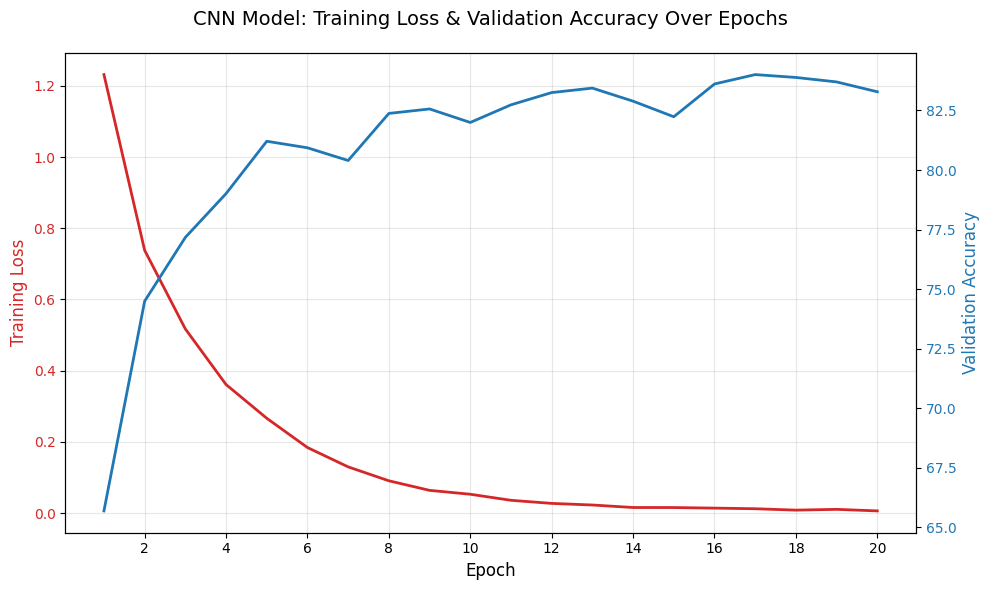

✅ CNN plot saved as 'cnn_training_curves.png'
PART 3(b) COMPLETE!


In [4]:
# ============================================================================
# PART 3(b): CNN - DUAL Y-AXIS (MATCHING YOUR SCREENSHOT)
# ============================================================================

import torch
import torch.nn as nn
import torch.optim as optim
from torchtext import data
import numpy as np
import matplotlib.pyplot as plt
import random

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}\n')

# Config
BATCH_SIZE = 64
N_EPOCHS = 20
LEARNING_RATE = 1e-3
N_FILTERS = 100
FILTER_SIZES = [3, 4, 5]
DROPOUT = 0.5
GRAD_CLIP = 1.0

# split train and validation data
train_data, valid_data = train_data.split(split_ratio=0.85, random_state=random.seed(42))

# Create iterators
train_iterator, valid_iterator, test_iterator = data.BucketIterator.splits(
    (train_data, valid_data, test_data),
    batch_size=BATCH_SIZE,
    sort_within_batch=True,
    sort_key=lambda x: len(x.text),
    device=device
)

# Get embeddings
vocab_size = len(TEXT.vocab)
output_size = len(LABEL.vocab)
embedding_dim = TEXT.vocab.vectors.size(1)
pretrained_embeddings = TEXT.vocab.vectors
PAD_IDX = TEXT.vocab.stoi[TEXT.pad_token]
UNK_IDX = TEXT.vocab.stoi[TEXT.unk_token]

print(f"Vocab size: {vocab_size}")
print(f"Classes: {output_size}")
print(f"Embedding dim: {embedding_dim}\n")

# Helper functions
def categorical_accuracy(preds, y):
    top_pred = preds.argmax(1)
    correct = top_pred.eq(y).sum().item()
    return correct / y.size(0)

def train_epoch(model, iterator, optimizer, criterion):
    model.train()
    epoch_loss = 0
    epoch_acc = 0

    for batch in iterator:
        text, text_lengths = batch.text
        if text.dim() == 2 and text.size(0) != text_lengths.size(0):
            text = text.transpose(0, 1)
        labels = batch.label.long().to(device)

        optimizer.zero_grad()
        predictions = model(text, text_lengths)
        loss = criterion(predictions, labels)
        acc = categorical_accuracy(predictions, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        optimizer.step()

        epoch_loss += loss.item()
        epoch_acc += acc

    return epoch_loss / len(iterator), epoch_acc / len(iterator)

def evaluate(model, iterator, criterion):
    model.eval()
    epoch_loss = 0
    epoch_acc = 0

    with torch.no_grad():
        for batch in iterator:
            text, text_lengths = batch.text
            if text.dim() == 2 and text.size(0) != text_lengths.size(0):
                text = text.transpose(0, 1)
            labels = batch.label.long().to(device)

            predictions = model(text, text_lengths)
            loss = criterion(predictions, labels)
            acc = categorical_accuracy(predictions, labels)

            epoch_loss += loss.item()
            epoch_acc += acc

    return epoch_loss / len(iterator), epoch_acc / len(iterator)

# ============================================================================
# CNN MODEL
# ============================================================================
print("="*80)
print("TRAINING CNN")
print("="*80)

class CNN(nn.Module):
    def __init__(self, vocab_size, embedding_dim, n_filters, filter_sizes, output_dim, dropout, pad_idx):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)
        self.convs = nn.ModuleList([nn.Conv2d(1, n_filters, (fs, embedding_dim)) for fs in filter_sizes])
        self.fc = nn.Linear(len(filter_sizes) * n_filters, output_dim)
        self.dropout = nn.Dropout(dropout)
        self.filter_sizes = filter_sizes

    def forward(self, text, text_lengths):
        embedded = self.embedding(text).unsqueeze(1)
        conved = []
        seq_len = embedded.size(2)

        for i, conv in enumerate(self.convs):
            filter_size = self.filter_sizes[i]
            if filter_size > seq_len:
                pad_size = filter_size - seq_len
                padded = torch.nn.functional.pad(embedded, (0, 0, 0, pad_size, 0, 0, 0, 0))
                conv_result = torch.relu(conv(padded))
            else:
                conv_result = torch.relu(conv(embedded))

            conv_result = conv_result.squeeze(3)
            pooled = torch.nn.functional.max_pool1d(conv_result, conv_result.shape[2])
            conved.append(pooled.squeeze(2))

        cat = torch.cat(conved, dim=1)
        cat = self.dropout(cat)
        return self.fc(cat)

# Train CNN
cnn_model = CNN(vocab_size, embedding_dim, N_FILTERS, FILTER_SIZES, output_size, DROPOUT, PAD_IDX)
cnn_model.embedding.weight.data.copy_(pretrained_embeddings)
cnn_model.embedding.weight.data[UNK_IDX] = torch.zeros(embedding_dim)
cnn_model.embedding.weight.data[PAD_IDX] = torch.zeros(embedding_dim)
cnn_model = cnn_model.to(device)

optimizer = optim.Adam(cnn_model.parameters(), lr=LEARNING_RATE)
criterion = nn.CrossEntropyLoss().to(device)

best_valid_acc = 0
cnn_train_losses, cnn_valid_accs = [], []

for epoch in range(N_EPOCHS):
    train_loss, train_acc = train_epoch(cnn_model, train_iterator, optimizer, criterion)
    valid_loss, valid_acc = evaluate(cnn_model, valid_iterator, criterion)
    cnn_train_losses.append(train_loss)
    cnn_valid_accs.append(valid_acc * 100)
    if valid_acc > best_valid_acc:
        best_valid_acc = valid_acc
        torch.save(cnn_model.state_dict(), 'cnn_model.pt')
    print(f'Epoch {epoch+1:02} | Train Loss: {train_loss:.3f} Acc: {train_acc*100:.2f}% | Valid Loss: {valid_loss:.3f} Acc: {valid_acc*100:.2f}%')

cnn_model.load_state_dict(torch.load('cnn_model.pt'))
test_loss, test_acc = evaluate(cnn_model, test_iterator, criterion)

print(f'\n{"="*80}')
print(f'---- Loading best CNN model for final test evaluation ----')
print(f'\nFinal CNN Test Loss: {test_loss:.3f} | Final CNN Test Accuracy: {test_acc*100:.2f}%')
print(f'Final CNN Test Accuracy: {test_acc*100:.2f}%')
print(f'{"="*80}\n')

# Plot CNN - DUAL Y-AXES
epochs = list(range(1, N_EPOCHS+1))

fig, ax1 = plt.subplots(figsize=(10, 6))

# Left Y-axis - Training Loss (RED)
color_loss = 'tab:red'
ax1.set_xlabel('Epoch', fontsize=12)
ax1.set_ylabel('Training Loss', color=color_loss, fontsize=12)
ax1.plot(epochs, cnn_train_losses, color=color_loss, linewidth=2)
ax1.tick_params(axis='y', labelcolor=color_loss)
ax1.set_xticks(epochs[1::2])  # Show 2, 4, 6, 8, 10, 12, 14, 16, 18, 20
ax1.grid(True, alpha=0.3)

# Right Y-axis - Validation Accuracy (BLUE)
ax2 = ax1.twinx()
color_acc = 'tab:blue'
ax2.set_ylabel('Validation Accuracy', color=color_acc, fontsize=12)
ax2.plot(epochs, cnn_valid_accs, color=color_acc, linewidth=2)
ax2.tick_params(axis='y', labelcolor=color_acc)

plt.title('CNN Model: Training Loss & Validation Accuracy Over Epochs', fontsize=14, pad=20)
fig.tight_layout()
plt.savefig('cnn_training_curves.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ CNN plot saved as 'cnn_training_curves.png'")
print("="*80)
print("PART 3(b) COMPLETE!")
print("="*80)